# 02 · Análisis exploratorio ponderado

Caracterización de la PEA de Guayas con factores de expansión (objetivo específico 1). Usa la base del INEC y `base_modelado.pkl` del notebook 01.

## 1. Carga de datos

In [1]:
import pandas as pd
import numpy as np
import pyreadstat
import matplotlib.pyplot as plt

ruta = "Datos/BDDenemdu_personas_2025_anual.sav"

In [2]:
df25, meta25 = pyreadstat.read_sav(ruta)
base = pd.read_pickle("base_modelado.pkl")

# PEA de Guayas con las variables originales (mismo filtro del notebook 01)
df25['prov'] = df25['ciudad'].astype('Int64').astype(str).str.zfill(6).str[:2]
gy = df25[df25['prov'] == '09'].copy()
pea25 = gy[gy['condact'].between(1, 8) & (gy['condact'] != 6)].copy()
pea25['y'] = (pea25['condact'] == 1).astype(int)

print("PEA Guayas:", len(pea25), "| Base de modelado:", base.shape)

PEA Guayas: 19525 | Base de modelado: (19525, 22)


## 2. Guayas frente al país

In [3]:
# Tasa de empleo adecuado ponderada: país frente a Guayas
pea_nac = df25[df25['condact'].between(1, 8) & (df25['condact'] != 6)]
tasa_nac = ((pea_nac['condact'] == 1) * pea_nac['fexp']).sum() / pea_nac['fexp'].sum() * 100
tasa_gy = (base['y'] * base['fexp']).sum() / base['fexp'].sum() * 100

print("Nacional:", round(tasa_nac, 1), "%")
print("Guayas:  ", round(tasa_gy, 1), "%")

Nacional: 37.2 %
Guayas:   41.5 %


## 3. Sobremuestreo de Guayaquil (Tabla 6)

In [4]:
# Peso de cada zona en la muestra (casos) y en la población (fexp)
zonas = ['Guayaquil', 'Conurbación', 'Resto urbano', 'Resto rural']

t2 = base.groupby('zona_amp').apply(lambda d: pd.Series({
    'casos': len(d),
    'pct_casos': len(d) / len(base) * 100,
    'pct_ponderado': d['fexp'].sum() / base['fexp'].sum() * 100})).loc[zonas]

print(t2.round(1))
t2.round(1).to_csv("T2_sobremuestreo.csv", encoding="utf-8-sig")

                casos  pct_casos  pct_ponderado
zona_amp                                       
Guayaquil     16147.0       82.7           61.7
Conurbación    1293.0        6.6           10.4
Resto urbano   1080.0        5.5           20.4
Resto rural    1005.0        5.1            7.4


## 4. Tasas ponderadas por variable (categorías originales)

In [5]:
categoricas = ['p02', 'p04', 'p06', 'p15', 'p15aa', 'nnivins', 'p07', 'area', 'dominio']

for v in categoricas:
    g = pea25.groupby(v).apply(lambda d: pd.Series({
        'n': len(d),
        'pct_pea': d['fexp'].sum() / pea25['fexp'].sum() * 100,
        'tasa_adecuado': (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100
    }))
    g.index = g.index.map(meta25.variable_value_labels.get(v, {}))
    print(f"\n=== {v}: {meta25.column_names_to_labels.get(v)} ===")
    print(g.round(1))


=== p02: Sexo ===
              n  pct_pea  tasa_adecuado
p02                                    
Hombre  11835.0     64.3           44.6
Mujer    7690.0     35.7           36.0

=== p04: Relación de Parentesco ===
                               n  pct_pea  tasa_adecuado
p04                                                     
Jefe                      8752.0     46.7           43.7
Cónyuge                   3021.0     15.0           39.1
Hijo o Hija               5441.0     25.8           41.7
Yerno o nuera              559.0      4.0           43.1
Nieto o nieta              379.0      1.9           33.9
Padres o suegros           111.0      0.4           39.2
Otros parientes            991.0      4.6           32.7
Empleado(a) doméstico(a)    26.0      0.1           48.5
Otros no parientes         245.0      1.5           28.2

=== p06: Estado civil ===
                    n  pct_pea  tasa_adecuado
p06                                          
Casado(a)      4756.0     22.2        

## 5. Edad y sexo (Figura 3)

In [6]:
tramos = [15, 18, 25, 35, 45, 55, 65, 100]
nombres = ['15-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
pea25['tramo_edad'] = pd.cut(pea25['p03'], bins=tramos, labels=nombres, right=False)

def resumen_ponderado(d):
    return pd.Series({
        'n': len(d),
        'pct_pea': d['fexp'].sum() / pea25['fexp'].sum() * 100,
        'tasa_adecuado': (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100
    })

print("=== Edad por tramos ===")
print(pea25.groupby('tramo_edad', observed=True).apply(resumen_ponderado).round(1))

print("\n=== Tasa de empleo adecuado: asiste a clases según edad ===")
print(pea25.groupby(['tramo_edad', 'p07'], observed=True)
      .apply(lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100)
      .unstack().rename(columns={1.0: 'Asiste', 2.0: 'No asiste'}).round(1))

=== Edad por tramos ===
                 n  pct_pea  tasa_adecuado
tramo_edad                                
15-17         79.0      0.8            0.7
18-24       2506.0     13.6           32.1
25-34       4519.0     23.8           49.8
35-44       4238.0     23.8           46.1
45-54       4076.0     18.8           47.0
55-64       2783.0     13.4           33.2
65+         1324.0      5.8           18.3

=== Tasa de empleo adecuado: asiste a clases según edad ===
p07         Asiste  No asiste
tramo_edad                   
15-17          0.0        1.0
18-24         25.4       33.2
25-34         54.9       49.4
35-44         73.0       45.4
45-54         45.8       47.1
55-64         55.6       33.1
65+            0.0       18.3


p02         Hombre  Mujer
tramo_edad               
15-17          0.7    0.0
18-24         33.2   29.4
25-34         55.6   40.7
35-44         52.0   37.2
45-54         52.9   36.5
55-64         32.6   34.4
65+           17.3   20.8


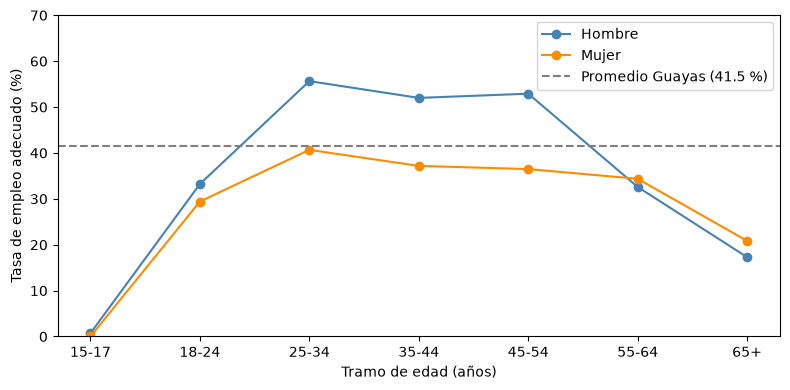

In [7]:
# Tasa por tramo de edad y sexo
tasa_edad_sexo = pea25.groupby(['tramo_edad', 'p02'], observed=True).apply(
    lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100).unstack()
tasa_edad_sexo = tasa_edad_sexo.rename(columns={1.0: 'Hombre', 2.0: 'Mujer'})
print(tasa_edad_sexo.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(nombres, tasa_edad_sexo['Hombre'], marker='o', color='steelblue', label='Hombre')
ax.plot(nombres, tasa_edad_sexo['Mujer'], marker='o', color='darkorange', label='Mujer')
ax.axhline(tasa_gy, color='gray', linestyle='--', label=f'Promedio Guayas ({tasa_gy:.1f} %)')
ax.set_xlabel('Tramo de edad (años)')
ax.set_ylabel('Tasa de empleo adecuado (%)')
ax.set_ylim(0, 70)
ax.legend()
plt.tight_layout()
plt.savefig("F_tasa_por_edad_sexo.png", dpi=300)
plt.show()

## 6. Zona de residencia (Figura 4)

In [8]:
print("=== Casos (sin ponderar) ===")
print(pd.crosstab(pea25['dominio'], pea25['area'], margins=True)
      .rename(index={2.0: 'Guayaquil', 6.0: 'Resto Guayas'},
              columns={1.0: 'Urbana', 2.0: 'Rural'}))

print("\n=== Tasa de empleo adecuado (ponderada) ===")
print(pea25.groupby(['dominio', 'area'])
      .apply(lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100)
      .unstack()
      .rename(index={2.0: 'Guayaquil', 6.0: 'Resto Guayas'},
              columns={1.0: 'Urbana', 2.0: 'Rural'})
      .round(1))

=== Casos (sin ponderar) ===
area          Urbana  Rural    All
dominio                           
Guayaquil      16147      0  16147
Resto Guayas    1963   1415   3378
All            18110   1415  19525

=== Tasa de empleo adecuado (ponderada) ===
area          Urbana  Rural
dominio                    
Guayaquil       49.4    NaN
Resto Guayas    30.7   22.8


zona_amp
Guayaquil       49.4
Conurbación     45.1
Resto urbano    23.9
Resto rural     19.5
dtype: float64


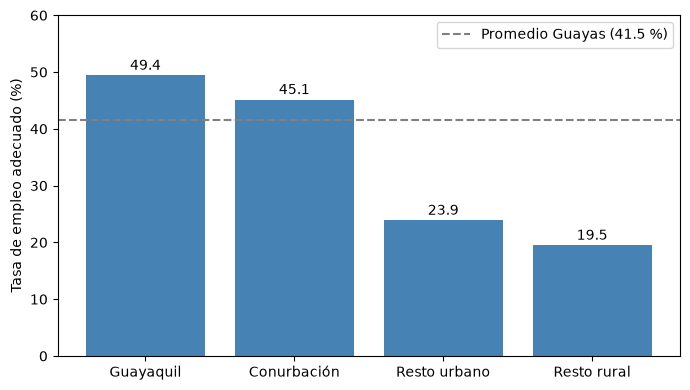

In [9]:
# Tasa por zona ampliada
tasa_zona = base.groupby('zona_amp').apply(
    lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100).loc[zonas]
print(tasa_zona.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tasa_zona.index, tasa_zona.values, color='steelblue')
ax.axhline(tasa_gy, color='gray', linestyle='--', label=f'Promedio Guayas ({tasa_gy:.1f} %)')
for i, v in enumerate(tasa_zona.values):
    ax.text(i, v + 1, f'{v:.1f}', ha='center')
ax.set_ylabel('Tasa de empleo adecuado (%)')
ax.set_ylim(0, 60)
ax.legend()
plt.tight_layout()
plt.savefig("F2_tasa_por_zona.png", dpi=300)
plt.show()

## 7. Educación y título superior (Figura 5)

In [10]:
# Tasa por nivel de instrucción
niveles = ['Ninguno', 'Básica', 'Media/Bachillerato', 'Superior sin título', 'Superior con título']
tasa_instr = base.groupby('instruccion').apply(
    lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100).loc[niveles]
print(tasa_instr.round(1))

# Entre los titulados: nivel y campo del título
con_titulo = base[base['instruccion'] == 'Superior con título']
for v in ['tit_nivel', 'tit_campo']:
    g = con_titulo.groupby(v).apply(lambda d: pd.Series({
        'n': len(d),
        'tasa_adecuado': (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100}))
    print(f"\n=== {v} ===")
    print(g.sort_values('tasa_adecuado', ascending=False).round(1).to_string())

instruccion
Ninguno                11.1
Básica                 26.4
Media/Bachillerato     45.4
Superior sin título    52.3
Superior con título    70.3
dtype: float64

=== tit_nivel ===
                  n  tasa_adecuado
tit_nivel                         
Postgrado     501.0           89.8
Tecnológico   544.0           70.1
Grado        2769.0           68.0
Técnico       115.0           54.8

=== tit_campo ===
                                  n  tasa_adecuado
tit_campo                                         
Servicios                     213.0           80.6
Ingeniería                    520.0           76.7
Educación                     673.0           73.7
Salud                         394.0           72.0
Otros campos                  124.0           70.5
Administración               1028.0           69.2
Ciencias sociales y derecho   568.0           65.0
TIC                           256.0           57.1
Artes y humanidades           153.0           56.2


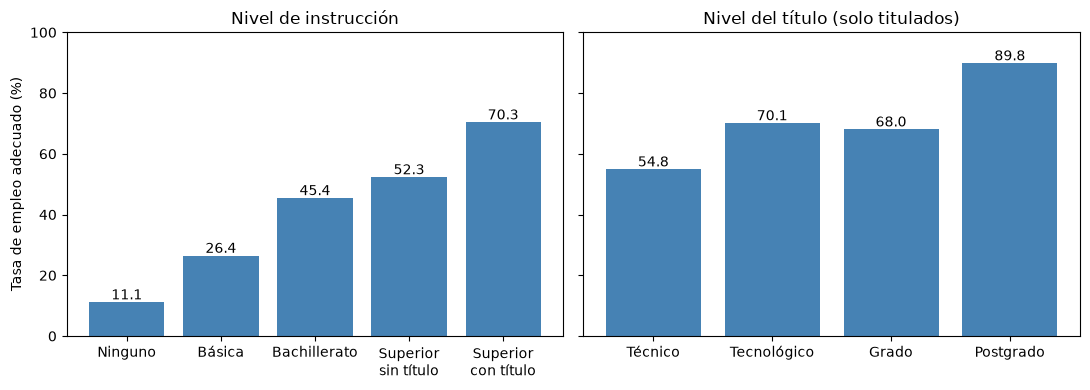

In [11]:
titulos = ['Técnico', 'Tecnológico', 'Grado', 'Postgrado']
tasa_tit = con_titulo.groupby('tit_nivel').apply(
    lambda d: (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100).loc[titulos]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax1.bar(range(len(niveles)), tasa_instr.values, color='steelblue')
ax1.set_xticks(range(len(niveles)))
ax1.set_xticklabels(['Ninguno', 'Básica', 'Bachillerato', 'Superior\nsin título', 'Superior\ncon título'])
ax1.set_title('Nivel de instrucción')
ax1.set_ylabel('Tasa de empleo adecuado (%)')

ax2.bar(titulos, tasa_tit.values, color='steelblue')
ax2.set_title('Nivel del título (solo titulados)')

for ax, valores in [(ax1, tasa_instr.values), (ax2, tasa_tit.values)]:
    for i, v in enumerate(valores):
        ax.text(i, v + 1, f'{v:.1f}', ha='center')
ax1.set_ylim(0, 100)

plt.tight_layout()
plt.savefig("F3_tasa_por_educacion.png", dpi=300)
plt.show()

## 8. Tabla de caracterización

Estimaciones puntuales ponderadas. Los intervalos de confianza con el diseño muestral completo salen del script de R.

In [12]:
c = base.copy()
c['sexo'] = c['p02'].map({1: 'Hombre', 2: 'Mujer'})
c['tramo_edad'] = pd.cut(c['p03'], bins=tramos, labels=nombres, right=False)

filas = []
for v in ['sexo', 'tramo_edad', 'parentesco', 'etnia', 'instruccion', 'tit_nivel', 'zona_amp']:
    g = c.groupby(v, observed=True).apply(lambda d: pd.Series({
        'n': len(d),
        'pct_pea': d['fexp'].sum() / c['fexp'].sum() * 100,
        'tasa_adecuado': (d['y'] * d['fexp']).sum() / d['fexp'].sum() * 100}))
    g.insert(0, 'variable', v)
    filas.append(g)

t4 = pd.concat(filas)
t4.index.name = 'categoria'
print(t4.round(1).to_string())
t4.round(1).to_csv("T4_caracterizacion.csv", encoding="utf-8-sig")

                        variable        n  pct_pea  tasa_adecuado
categoria                                                        
Hombre                      sexo  11835.0     64.3           44.6
Mujer                       sexo   7690.0     35.7           36.0
15-17                 tramo_edad     79.0      0.8            0.7
18-24                 tramo_edad   2506.0     13.6           32.1
25-34                 tramo_edad   4519.0     23.8           49.8
35-44                 tramo_edad   4238.0     23.8           46.1
45-54                 tramo_edad   4076.0     18.8           47.0
55-64                 tramo_edad   2783.0     13.4           33.2
65+                   tramo_edad   1324.0      5.8           18.3
Cónyuge               parentesco   3021.0     15.0           39.1
Hijo/a                parentesco   5441.0     25.8           41.7
Jefe                  parentesco   8752.0     46.7           43.7
Otros                 parentesco   2311.0     12.6           36.0
Afrodescen